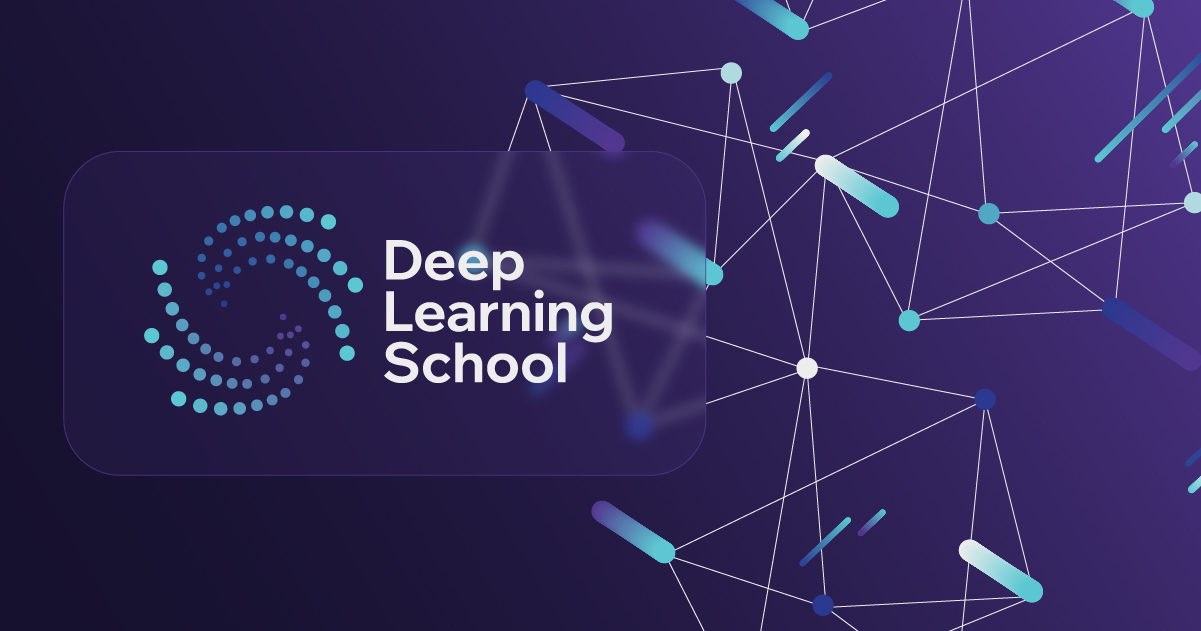

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Библиотека sklearn и классификация с помощью KNN</b></h1>

## Описание домашнего задания

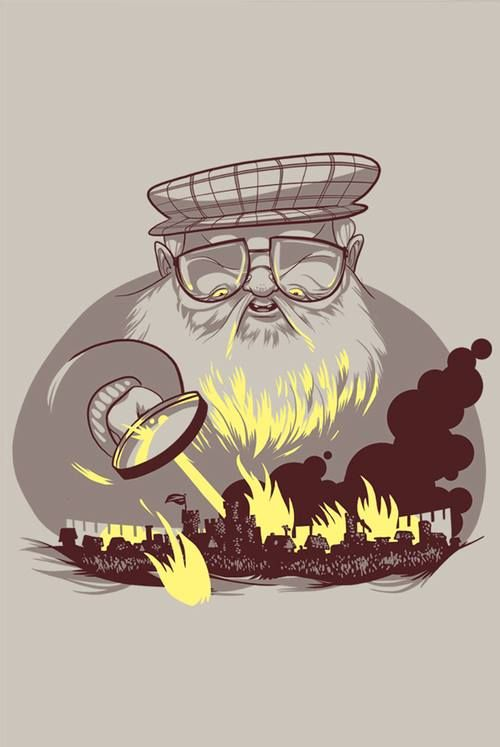

В данном задании вы будете работать с датасетом о персонажах из вселенной Игры Престолов [A Wiki of Ice and Fire](http://awoiaf.westeros.org/). Вам предстоит предсказать, кто из персонажей умрет, а кто останется вживых.



Описание данных:

* **name**: Имя персонажа

* **Title**: Социальный статус или знатность

* **House**: Дом, к которому принадлежит персонаж

* **Culture**: Социальная группа, к которой принадлежит персонаж

* **book1/2/3/4/5**: Появление персонажа в книге

* **Is noble**: Знатность персонажа, основанное на титуле

* **Age**: Отсчет времени: 305 AC

* **male**: Мужчина или женщина

* **dateOfBirth**: дата рождения

* **Spouse**: Имя супруги\а персонажа

* **Father**: Имя отца персонажа

* **Mother**: Имя матери персонажа

* **Heir**: Имя наследника персонажа

* **Is married**: Represents whether the character is married

* **Is spouse alive**: Represents whether character's spouse is alive

* **Is mother alive:** Жива ли мать персонажа

* **Is heir alive:** Жив ли наследник персонажа

* **Is father alive:** Указывает, жив ли отец персонажа

* **Number dead relations:** Количество умерших персонажей, с которыми персонаж связан

* **Popularity score:** Количество внутренних входящих и исходящих ссылок на страницу персонажей в вики http://awoiaf.westeros.org

Целевая переменная:
* **isAlive**: жив ли персонаж в книге

Оценивание:

Баллы считаются следующим образом:

1) $1.00 \geqslant score \geqslant 0.65$ --- 5 баллов

2) $0.65 > score \geqslant 0.50$ --- 4 балла

3) $0.50 > score \geqslant 0.45$ --- 3 балла

4) $0.45 > score \geqslant 0.40$ --- 2 балла

5) $0.40 > score \geqslant 0.35$ --- 1 балл

6) $0.35 > score$ --- 0 баллов

## Часть 1. Анализ и предобработка данных

Здесь вам необходимо сделать все шаги, которые обсуждались в первой части семинара.
* Предобработка данных
  * Обработка пропущенных данных
  * Создание новых признаков
  * Удаление ненужных столбцов
* Анализ данных
  * Анализ целевой переменной
  * Анализ признаков
  * Анализ влияния признаков на целевую переменную
* Подготовка данных для обучения модели

Загружаем датасет

In [1667]:
!gdown 1h99toeF7lZ2I3iJwehgKO-QQmDaOe_O3 # test dataset
!gdown 1XL0VTygpZj-ZAuTNRBgApZTPQyNDnT-v # train dataset

zsh:1: command not found: gdown
zsh:1: command not found: gdown


**Задание 1.1.** Импортируйте библиотеки pandas, matplotlib, seaborn

In [1668]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Перед началом выполнения заданий, настроим стиль графиков

In [1669]:
CUSTOM_STYLE = "darkgrid"

CUSTOM_RC ={
    # Background
    'figure.facecolor': '#121212',
    'axes.facecolor': '#121212',

    #text
    'text.color': '#E0E0E0',
    'axes.labelcolor': '#E0E0E0',

    # Axis and numbers:
    'xtick.color': '#9E9E9E',
    'ytick.color': '#9E9E9E',
    'axes.edgecolor': '#424242',
    
    # Grid
    'grid.color': '#2C2C2C',

    # drop right and left edge
    'axes.spines.top': False,
    'axes.spines.right': False
}

CUSTOM_PALETTE = ['#03DAC6', '#BB86FC', '#CF6679', '#FFB74D', '#64B5F6']

In [1670]:
sns.set_theme(style=CUSTOM_STYLE, rc=CUSTOM_RC, palette=CUSTOM_PALETTE)

**Задание 1.2.** Загрузите датасет в Pandas DataFrame при помощи функции `read_csv`. Вместо дефолтных наименований строк `0,1,...`, при помощи параметра `index_col`, сделайте значения колонки `S.No` наименованиями строк:

In [1671]:
data = pd.read_csv("../data/game_of_thrones_train.csv", index_col="S.No")

In [1672]:
data.head()

,name,title,male,culture,dateOfBirth,mother,father,heir,house,spouse,...,isAliveMother,isAliveFather,isAliveHeir,isAliveSpouse,isMarried,isNoble,age,numDeadRelations,popularity,isAlive
S.No,,,,,,,,,,,,,,,,,,,,,
1,Viserys II Targaryen,NaN,1,NaN,NaN,Rhaenyra Targaryen,Daemon Targaryen,Aegon IV Targaryen,NaN,NaN,...,1.0,0.0,0.0,NaN,0,0,NaN,11,0.605351,0
2,Walder Frey,Lord of the Crossing,1,Rivermen,208.0,NaN,NaN,NaN,House Frey,Perra Royce,...,NaN,NaN,NaN,1.0,1,1,97.0,1,0.896321,1
3,Addison Hill,Ser,1,NaN,NaN,NaN,NaN,NaN,House Swyft,NaN,...,NaN,NaN,NaN,NaN,0,1,NaN,0,0.267559,1
4,Aemma Arryn,Queen,0,NaN,82.0,NaN,NaN,NaN,House Arryn,Viserys I Targaryen,...,NaN,NaN,NaN,0.0,1,1,23.0,0,0.183946,0
5,Sylva Santagar,Greenstone,0,Dornish,276.0,NaN,NaN,NaN,House Santagar,Eldon Estermont,...,NaN,NaN,NaN,1.0,1,1,29.0,0,0.043478,1


Посмотрите, какие типы данных представлены в нашем датасете

In [1673]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1557 entries, 1 to 1557
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              1557 non-null   str    
 1   title             717 non-null    str    
 2   male              1557 non-null   int64  
 3   culture           488 non-null    str    
 4   dateOfBirth       279 non-null    float64
 5   mother            18 non-null     str    
 6   father            22 non-null     str    
 7   heir              21 non-null     str    
 8   house             1176 non-null   str    
 9   spouse            200 non-null    str    
 10  book1             1557 non-null   int64  
 11  book2             1557 non-null   int64  
 12  book3             1557 non-null   int64  
 13  book4             1557 non-null   int64  
 14  book5             1557 non-null   int64  
 15  isAliveMother     18 non-null     float64
 16  isAliveFather     22 non-null     float64
 17  isAliv

Знакомый нам метод describe() возвращает различную информацию для столбцов с числовыми типами данных, и с типами данных *object*

Давайте посмотрим на вывод для типа данных *object*. Для этого:
- сначала применим метод describe(). Укажем в качестве аргумента тип данных столбцов, статистику по которым мы хотим посмотреть (см. https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html)
- для удобства восприятия транспонируем таблицу

In [1674]:
data.describe(include = 'object').T

/var/folders/7y/zkjqsj6d22z6cf_q2mv7cgsm0000gn/T/ipykernel_15115/824788996.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  data.describe(include = 'object').T


,count,unique,top,freq
name,1557,1557,Viserys II Targaryen,1
title,717,195,Ser,306
culture,488,51,Northmen,94
mother,18,16,Rhaenyra Targaryen,2
father,22,19,Daemon Targaryen,2
heir,21,20,Jaehaerys Targaryen,2
house,1176,315,House Frey,89
spouse,200,186,Walder Frey,6


Теперь давайте посмотрим на столбцы с числовыми типами данных. Дополните код ниже. Для удобства восприятия мы транспонировали таблицу и ограничили вывод тремя столбцами - количество строк без NaN, максимальное и минимальное значение (о кастомизации вариантах вывода describe() вы можете почитать в документации по ссылке выше).


In [1675]:
data.describe(include = ['int64', 'float64']).T[['count', 'min', 'max']]

,count,min,max
male,1557.0,0.0,1.0
dateOfBirth,279.0,-25.0,299.0
book1,1557.0,0.0,1.0
book2,1557.0,0.0,1.0
book3,1557.0,0.0,1.0
book4,1557.0,0.0,1.0
book5,1557.0,0.0,1.0
isAliveMother,18.0,0.0,1.0
isAliveFather,22.0,0.0,1.0
isAliveHeir,21.0,0.0,1.0


Так мы проверим, есть ли в данных неадекватнные значения.   Большинство числовых столбцов - это числа от 0 до 1. Отрицательные значения `dateOfBirth` не являются ошибкой. Значения age и `numDeadRelations` также выглядят адекватными. Можно переходить к дальнейшим шагам анализа (анонс - а в тестовых данных нас будет ждать сюрприз).

**Задание 1.3.** Предобработка (очистка) данных.

В нашем домашнем задании все пропуски в данных (missing values) уже закодированы как NaN. Проанализируйте, в каких колонках и как часто встречаются NaN значения. Далее вам надо будет принять решение, как их обрабатывать.

In [1676]:
# Убираем колонки, где нет пропусков и сортируем по убыванию (Для удобства)

data.isna().sum()[lambda field: field > 0].sort_values(ascending=False)

mother           1539
isAliveMother    1539
heir             1536
isAliveHeir      1536
father           1535
isAliveFather    1535
spouse           1357
isAliveSpouse    1357
dateOfBirth      1278
age              1278
culture          1069
title             840
house             381
dtype: int64

В этом задании удалять строки с NaN (dropna) мы не будем по следующим причинам:
- в обучающем датасете много признаков с большим количество пропусков. Если удалять все строки с NaN, то размер выборки сильно уменьшится. Мы потеряем много данных, которые можно было бы использовать для построения более точной модели.
- тестовом датасете также много признаков с NaN (вы можете в этом убедиться, если скачаете датасет и совершите с ним те же действия, что выше проделали с обучаюшим датасетом). Поэтому нам все-равно придется придумать способ кодировать NaN, чтобы модель делала прогнозы для всех персонажей из тестового датасета. Для этого нам потребуется сохранять, а не удалять данные в обучающем датасете.     



Как вы могли заметить, в наших данных очень много пропущенных значений, причём в некоторых случая пропущена **большая** часть значений. Поэтому заполнять по умолчанию медианой/средним/модой в данном случае - не самый лучший способ (однако, это довольно часто используемый метод заполнения, который может пригодиться вам в будущем)

Ниже мы посмотрим, как можно работать с признаками с большим количеством пропущенных значений.

**Задание 1.4.** Числовые признаки

У нас есть **признак popularity**. Постройте гистограмму распределения данного признака с количеством интервалов (bins), равным 50 (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.hist.html)

<Axes: xlabel='popularity', ylabel='Count'>

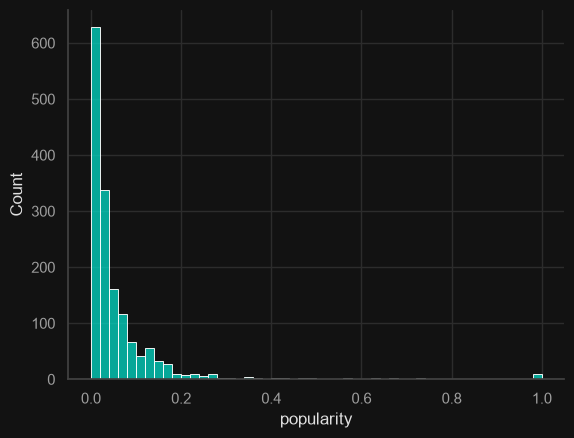

In [1677]:
sns.histplot(x=data["popularity"], bins=50)

Распределение сильно несимметрично. Можно преобразовать данный признак, например, по формуле `np.log10(data["popularity"]*M+1)` (добавляем 1 ради логарифма, так как для некоторых персонажей `popularity==0`). В качестве M можно попробовать, например, M=100 или другое число.

При желании для `popularity` вы можете использовать свой способ шкалирования признаков с несимметричным распределением.


В качестве альтернативного подхода вы можете попробовать дискретизацию признака popularity на основе квантилей (quantile binning), используя функцию qcut() (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.qcut.html). В этом случае вы преобразуете числовой признак popularity в категориальный, для которого в дальнейшем надо будет применить one-hot кодирование.

Поэкспериментируем с разными способоми. Попробуем:
1. Извлечение корня (квадратного или кубического)
2. Логарифмирование
3. Адаптивный подбор степени

In [1678]:
import numpy as np
from sklearn.preprocessing import PowerTransformer

In [1679]:
# Базовое распределение

distribution = data["popularity"]

# 1. Извлечение корня

distribution_1 = np.sqrt(distribution)
distribution_2 = np.cbrt(distribution)

# 2. Логарифмирование

M = 100
distribution_3 = np.log10(distribution*M+1)

# 3. Адаптивный подбор степени

pt = PowerTransformer(method="yeo-johnson")
distribution_pt = pd.Series(pt.fit_transform(data[["popularity"]])[:, 0], name="popularity", index=data.index)

Разберм адаптивный подбор степени (посмотрим аргумент лямбда)

In [1680]:
# lambda = 0 - лучше использовать логарифм
# 0.3 <= lambda <= 0.7 - лучше использовать извлечение квадратного или кубического корня
# lambda = 1 - распределение уже было симметричным
# lambda < 0 - требуется сильное сжатие

pt.lambdas_

array([-14.01119109])

Построим график и сравним распределения

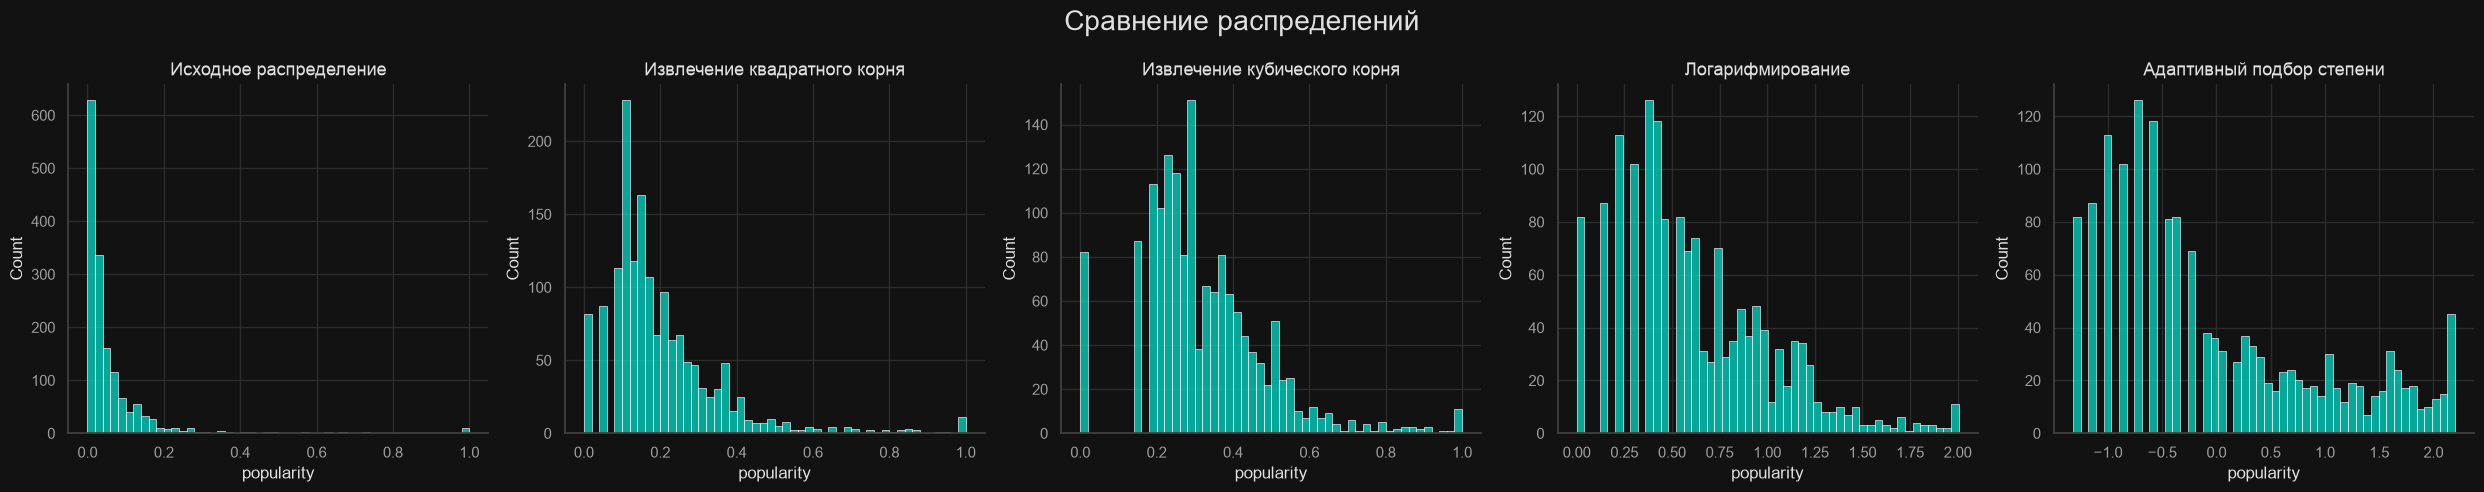

In [1681]:
fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(25, 5))
fig.suptitle("Сравнение распределений", size=20)

distributions = [distribution, distribution_1, distribution_2, distribution_3, distribution_pt]
labels_distributions = ["Исходное распределение", "Извлечение квадратного корня", "Извлечение кубического корня", "Логарифмирование", "Адаптивный подбор степени"]
for i, ax in enumerate(axes):
    sns.histplot(x=distributions[i], bins=50, ax=ax)
    ax.set_title(labels_distributions[i], size=13)

plt.tight_layout()
plt.show()

Самым лучшим распределением оказалось: Адаптивный подбор степени

In [1682]:
data["popularity"] = distribution_pt

Теперь давайте обработаем **признак numDeadRelations**.
Посмотрите на частотное распределение этого признака. Лишь для малого числа персонажей `numDeadRelations>0`.

Создайте признак `boolDeadRelations`. Давайте упростим признак `numDeadRelations`, и просто поделим людей на тех, у кого были хоть какие то отношения с мертвыми персонажами, т.е. `numDeadRelations > 0`, и те, у которых не было, т.е. `numDeadRelations = 0`.

In [1683]:
data["numDeadRelations"].value_counts()

numDeadRelations
0     1488
1       24
5       10
7        7
4        7
3        4
10       4
2        4
6        3
8        2
11       1
12       1
15       1
9        1
Name: count, dtype: int64

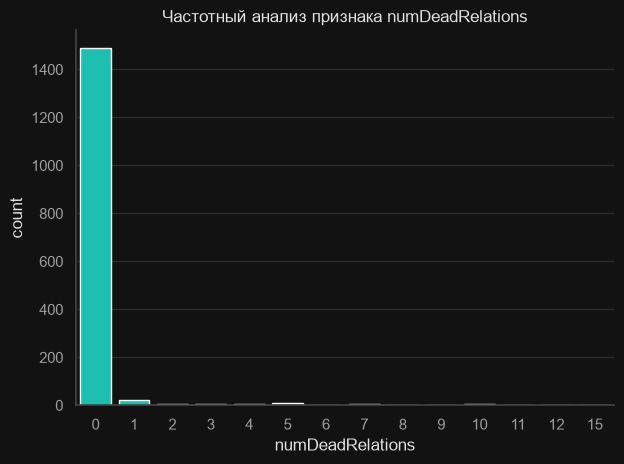

In [1684]:
plt.title("Частотный анализ признака numDeadRelations")
sns.countplot(x=data["numDeadRelations"])
plt.tight_layout()
plt.show()

In [1685]:
data.loc[data["numDeadRelations"] > 0, "boolDeadRelations"] = 1
data.loc[data["numDeadRelations"] == 0, "boolDeadRelations"] = 0

In [1686]:
data[["numDeadRelations", "boolDeadRelations"]].head()

,numDeadRelations,boolDeadRelations
S.No,,
1,11,1.0
2,1,1.0
3,0,0.0
4,0,0.0
5,0,0.0


In [1687]:
data.drop("numDeadRelations", axis=1, inplace=True)

Наконец, давайте посмотрим на **признак age**. В нем очень много пропущенных значений. Для того, чтобы использовать в модели информацию о возрасте персонажа, мы создадим два новых признака: `age_value` и `age_no_data`

- Там где возраст указан, age_value принимает значение `age`, а `age_no_data` - значение 0.
- Там где возраст не указан, `age_value` принимает значение 0, а `age_no_data` - значение 1.  

Фактически, в переменной `age` мы заменяем NaN на 0, но одновременно добавляем в модель еще один бинарный признак `age_no_data`, несущий информацию о том, у каких персонажей не был указан возраст:        

In [1688]:
data['age_value'] = [0 if np.isnan(x) else x for x in data["age"]]
data['age_no_data'] = [1 if np.isnan(x) else 0 for x in data['age']]

In [1689]:
data[["age", "age_value", "age_no_data"]].head()

,age,age_value,age_no_data
S.No,,,
1,NaN,0.0,1
2,97.0,97.0,0
3,NaN,0.0,1
4,23.0,23.0,0
5,29.0,29.0,0


In [1690]:
data.drop("age", axis=1, inplace=True)

Этот способ чем-то похож на работу с категориальной переменными с пропущенными значениями, когда мы добавляем еще одну категорию no_data и заменяем NaN на значение этой категории.

Если вы заходите похожим образом образом обработать признак `dateOfBirth`, **обратите внимание**, что у одних и тех же персонажей не указан и возраст, и год рождения.
То есть созданные признаки `age_no_data` и `dateOfBirth_no_data` будут полностью совпадать, и в модель надо будет включать только один из признаков: или `age_no_data`, или `dateOfBirth_no_data`.

In [1691]:
data["dateOfBirth_value"] = [0 if np.isnan(x) else x for x in data["dateOfBirth"]]

In [1692]:
data[["dateOfBirth", "dateOfBirth_value", "age_no_data"]].head()

,dateOfBirth,dateOfBirth_value,age_no_data
S.No,,,
1,NaN,0.0,1
2,208.0,208.0,0
3,NaN,0.0,1
4,82.0,82.0,0
5,276.0,276.0,0


In [1693]:
data.drop("dateOfBirth", axis=1, inplace=True)

**Задание 1.5.** Категориальные признаки с большим количеством категорий

**Признак culture** содержит информацию о принадлежности к одному из народов во вселенной Игры Престолов.

Давайте посмотрим, какие значения принимает данный признак. По умолчанию метод `value_counts()` игнорирует пропуски в данных, поэтому используем этот метод с параметром **dropna** со значением **False** (см. https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.value_counts.html)

In [1694]:
data['culture'].value_counts(dropna=False)

culture
NaN                        1069
Northmen                     94
Ironborn                     91
Free Folk                    45
Braavosi                     39
Valyrian                     28
Dornish                      17
Dothraki                     17
Ghiscari                     17
Reach                        13
Vale mountain clans          12
Rivermen                     10
Valemen                      10
northmen                      9
Westerman                     8
Free folk                     7
Tyroshi                       6
Qartheen                      5
Summer Isles                  4
Astapori                      4
Stormlands                    4
Ironmen                       3
Westeros                      3
Westermen                     3
Dornishmen                    3
Northern mountain clans       3
Lysene                        2
westermen                     2
First Men                     2
Meereenese                    2
Myrish                        2


Из полученного частотного распределения видно, что для большого числа персонажей значения данного признака не указаны. Также есть много редких значений признака, которые в выборке повторяются один или несколько раз. Причина отчасти в том, что один и тот же народ упоминается в нашем датасете под разными названиями.

Данную проблему мы попытаемся решить, сгруппировав народы в более крупные категории. Так мы одновременно решим проблему того, что один и тот же народ назван в выборке разными способами.

Предоженный вариант группировки имеет определенную логику. Выделяются следующие группы:
- старые нации, которые уже не сущевали как отдельные народы на момент повествования основной линии повествования романов, но отдельные потомки могли еще быть живы
- народы, проживающие в королевствах континента Весторос (для каждого королевства - своя группа)
- народы континента Эссос
- прочие народы

In [1695]:
cultures_grouped = {
    'Old Nations': ['valyrian', 'first men', 'andal', 'andals', 'rhoynar'],
    'the North': ['northmen', 'northern mountain clans', 'crannogmen'],
    'the Iron Islands': ['ironborn', 'ironborn', 'ironmen'],
    'the Mountain and the Vale': ['valemen', 'vale', 'vale mountain clans',
                              'sistermen'],
    'the Isles and Rivers': ['riverlands', 'rivermen'],
    'the Rock': ['westerman', 'westermen', 'westerlands'],
    'the Stormlands': ['stormlander', 'stormlands'],
    'the Reach': ['reach', 'reachmen', 'the reach'],
    'Dorne': ['dornish', 'dornishmen', 'dorne'],
    'Essos Nations': ['astapor', 'astapori', 'braavosi', 'braavos', 'tyroshi', 'lysene', 'lyseni',
                      'myrish', 'pentoshi', 'qartheen', 'qarth', 'dothraki',
                      'lhazarene', 'lhazareen','meereen', 'meereenese',
                      'norvoshi', 'qohor', 'summer isles', 'summer islands',
                      'summer islander', 'asshai', "asshai'i", 'norvos', 'ghiscari',
                      'ghiscaricari'],
    'Other Nations': ['ibbenese', 'westeros', 'free folk', 'wildling', 'wildlings', 'naathi']}

**Обратите внимание, что некоторые варианты названий народов встречаются только в тестовых данных, и не встречаются в обучающих данных.** Такая ситуация нередко случается на практике. Поэтому, после обработки обучающих данных и обучения модели важно задать для модели правило, как она должна обрабатывать "незнакомые" категории в категориальных признаках. Например, можно относить объекты с "незнакомой" категорией к некоторой существующей категории или указать формулу расчета для "незнакомой" категории.     

Предложенный вам словарь `cultures_grouped` составлен по всем значениям признака `culture`, встречающимся в тренировочном либо в тестовом датасете. Здесь важно, что все укрупненные категории (ключи/keys словаря `cultures_grouped`) представлены в обоих датасетах, а уникальные для тестового датасета названия народов - это отдельные названия народов внутри укрупненных категорий (значения/values словаря). Поэтому, когда вы будете работать с тестовыми - просто применяйте этот словарь без указания правила обработки "незнакомых" категорий.

Давайте приступим к кодировке значений признака culture.
Для этого сначала инвертируем словарь *cultures_grouped*

In [1696]:
#Довольно просто инвертировать словарь, где ключу соответствует одно значение
#В нашем случае ключу соответствует список значений.
#Ниже показан пример, как можно инвертировать такой словарь

d = {'A': ['a1', 'a2', 'a3'],
     'B': ['b1', 'b2', 'b3', 'b4']}

d_inverted = {}
for k in d.keys():
  for v in d[k]:
      d_inverted.update({v:k})

d_inverted

{'a1': 'A', 'a2': 'A', 'a3': 'A', 'b1': 'B', 'b2': 'B', 'b3': 'B', 'b4': 'B'}

In [1697]:
# По аналогии с примером выше инвертируйте словарь cultures_grouped

cultures_grouped_inverted = {}
for k in cultures_grouped.keys():
    for v in cultures_grouped[k]:
        cultures_grouped_inverted.update({v:k})

cultures_grouped_inverted

{'valyrian': 'Old Nations',
 'first men': 'Old Nations',
 'andal': 'Old Nations',
 'andals': 'Old Nations',
 'rhoynar': 'Old Nations',
 'northmen': 'the North',
 'northern mountain clans': 'the North',
 'crannogmen': 'the North',
 'ironborn': 'the Iron Islands',
 'ironmen': 'the Iron Islands',
 'valemen': 'the Mountain and the Vale',
 'vale': 'the Mountain and the Vale',
 'vale mountain clans': 'the Mountain and the Vale',
 'sistermen': 'the Mountain and the Vale',
 'riverlands': 'the Isles and Rivers',
 'rivermen': 'the Isles and Rivers',
 'westerman': 'the Rock',
 'westermen': 'the Rock',
 'westerlands': 'the Rock',
 'stormlander': 'the Stormlands',
 'stormlands': 'the Stormlands',
 'reach': 'the Reach',
 'reachmen': 'the Reach',
 'the reach': 'the Reach',
 'dornish': 'Dorne',
 'dornishmen': 'Dorne',
 'dorne': 'Dorne',
 'astapor': 'Essos Nations',
 'astapori': 'Essos Nations',
 'braavosi': 'Essos Nations',
 'braavos': 'Essos Nations',
 'tyroshi': 'Essos Nations',
 'lysene': 'Essos Na

Теперь создадим новый столбец с укрупненными значениями culture.

Для этого будем использовать метод `map()` с инвертированным словарем в качестве аргумента (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.map.html)

Обратите внимание, что в словаре названия народов указаны в нижнем регистре. А в датасете используется как нижний, так и верхний регистр. Поэтому перед применением метода `map()` переведем значения столбца culture в нижний регистр при помощи метода `str.lower()` (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.str.lower.html).

In [1698]:
data['culture_grouped'] = data['culture'].str.lower().map(cultures_grouped_inverted)

Осталось заменить все NaN в созданном столбце на категорию `culture_no_data`:

In [1699]:
data['culture_grouped'] = data['culture_grouped'].fillna("culture_no_data")

In [1700]:
data.drop("culture", axis=1, inplace=True)

Распределение сгруппированной переменной выглядит гораздо лучше. Но по прежнему есть несколько слабо представленых групп.

Дальнейшую работу с этим признаком проводите на свое усмотрение для повышения качества прогноза модели. Например, можно объединить несколько слабо представленных категорий в одну или применить другой подход.

**Задание 1.6.** Категориальные признаки в линейных моделях

Для включения категориальных признаков в линейную модель их нужно преобразовать в числовые признаки.

Если признак принимает одно из двух возможных значений (например, персонаж "появляется" или "не появляется" в 1-й книге), он напрямую кодируется в бинарный признак ("появляется" -> 1, "не появляется" -> 0). Если признак принимает больше двух значений, его можно преобразовать в несколько бинарных при помощи one-hot преобразования. В некоторых случаях бывает полезно объединить некоторые категории, как мы это поступили с признаком *culture*.

Порядковых признаков у нас в задаче нет, поэтому рассматривать их здесь мы не будем.

Для того, чтобы найти все порядковые признаки, посмотрим на количество уникальных значений, которые встречаются в столбцах. Для столбцов с типом object количество уникальных значений мы выводили  при помощи метода `describe()` в задании 1.2.

Чтобы посмотреть количество уникальных значений для всех столбцов, можно воспользоваться методом nunique() (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.nunique.html)

In [1701]:
# Количество уникальных значений в каждом столбце

data.nunique()

name                 1557
title                 195
male                    2
mother                 16
father                 19
heir                   20
house                 315
spouse                186
book1                   2
book2                   2
book3                   2
book4                   2
book5                   2
isAliveMother           2
isAliveFather           2
isAliveHeir             2
isAliveSpouse           2
isMarried               2
isNoble                 2
popularity            117
isAlive                 2
boolDeadRelations       2
age_value              72
age_no_data             2
dateOfBirth_value     106
culture_grouped        12
dtype: int64

In [1702]:
# Для числовых столбцов можно вывести в одну таблицу более детальную статистику, объединив выводы describe() и nunique()
# Код ниже требуется дополнить по аналогии с заданием 1.2.

data.describe(include = ["int64", "float64"]).T[['count', 'min', 'max']].assign(N_unique_values = data.nunique())

,count,min,max,N_unique_values
male,1557.0,0.000000,1.000000,2
book1,1557.0,0.000000,1.000000,2
book2,1557.0,0.000000,1.000000,2
book3,1557.0,0.000000,1.000000,2
book4,1557.0,0.000000,1.000000,2
book5,1557.0,0.000000,1.000000,2
isAliveMother,18.0,0.000000,1.000000,2
isAliveFather,22.0,0.000000,1.000000,2
isAliveHeir,21.0,0.000000,1.000000,2
isAliveSpouse,200.0,0.000000,1.000000,2


Посмотрев на количество уникальных значений мы можем выделить категориальные признаки. Например, `popularity` принимает значения от 0 до 1, но это непрерывный числовой признак. Остальные признаки со значениями от 0 до 1 - принимают только два значения, то есть являются бинарными.

Бинарные признаки без NaN полностью готовы для включения в модель. Некоторые бинарные признаки содержат пропуски, поэтому, если вы захотите включить их в модель, их потребуется обработать.

Для бинарных признаков их связь с зависимой переменной можно прикинуть по таблице корреляций. Для категориальных признаков с количеством значений больше двух (или с двумя значениями и NaN) можно сделать one-hot преобразования и посчитать корреряцию зависимой переменной с набором сгенерированных бинарных признаков.
В качестве альтернативного подхода можно использовать сравнение средних значений зависимой переменной для разных категорий исследуемого признака. Чем сильнее различаются средние значения целевой переменной между категориями, тем вероятнее, что данный признак связан с зависимой переменной.

In [1703]:
# попробуйте провести сравнение средних зависимой пременной isAlive для признака isAliveSpouse
# одним из приведенных ниже способов:

data.groupby('isAliveSpouse', dropna = False)['isAlive'].mean()

isAliveSpouse
0.0    0.619048
1.0    0.753165
NaN    0.786293
Name: isAlive, dtype: float64

In [1704]:
pd.pivot_table(data = data, values = 'isAlive', index = 'isAliveSpouse', aggfunc=['mean', 'count'], dropna=False)

,mean,count
,isAlive,isAlive
isAliveSpouse,,
0.0,0.619048,42
1.0,0.753165,158
NaN,0.786293,1357


**Задание 1.7.** Проанализируйте признаки.
  * Обработайте категориальные признаки и переведите их в числа. Можете выбрать любой кодировщик. Не забудьте, что потом аналогичным образом вам надо будет преобразовывать тестовый датасет, используя тот же алгоритм кодирования признаков.
  * Проанализируйте количественные признаки. Есть ли корреляция между признаками?

Перед кодированием признаков, выполним окончательную предобработку

In [1705]:
# Для признака name нам важна фамилия (род, к которому принадлежит персонаж), все остальное отсекаем

data["name"] = data["name"].map(lambda field: field.split(" ")[-1])
data.loc[(data["name"].map(data["name"].value_counts()) < 5), "name"] = "rarely_encoding"

Дальше смотрим, какие остались признаки, имеющие NaN

In [1706]:
data.isna().sum()[lambda field: field > 0].sort_values()

house             381
title             840
spouse           1357
isAliveSpouse    1357
father           1535
isAliveFather    1535
heir             1536
isAliveHeir      1536
mother           1539
isAliveMother    1539
dtype: int64

In [1707]:
def feature_preprocessing_ht(data: pd.DataFrame, col_name: str, num: int):
    """Ф-ция для группировки названия домов и титулов, т.к. имеются много одиночных названий"""
    
    data.loc[(pd.notna(data[col_name])) & (data[col_name].map(data[col_name].value_counts()) < num), col_name] = "rarely_encoding"
    data[col_name] = data[col_name].fillna(f"{col_name}_no_data")

In [1708]:
# Обработаем House, Title

feature_preprocessing_ht(data, "house", 5)
feature_preprocessing_ht(data, "title", 5)

In [1709]:
# В этой ф-ции применяем несколько трюков, как выше (оставляем только титул, группируем) + (обрабатываем isAlive..., как обработали age)

def feature_preprocessing_mfsh(data: pd.DataFrame, col_name: str, num: int):
    data[col_name] = [f"{col_name}_no_data" if pd.isna(x) else x.split(" ")[-1] for x in data[col_name]]
    data.loc[(data[col_name] != f"{col_name}_no_data") & (data[col_name].map(data[col_name].value_counts()) < num), col_name] = "rarely_encoding"

    isAliveName = "isAlive" + col_name.title()
    data[isAliveName + "_no_data"] = [1 if np.isnan(x) else 0 for x in data[isAliveName]]
    data[isAliveName] = [0 if np.isnan(x) else x for x in data[isAliveName]]

In [1710]:
# Обработаем Mother, Father, Spouse, Heir; А также isAlive для каждого из них

feature_preprocessing_mfsh(data, "mother", 5)
feature_preprocessing_mfsh(data, "father", 5)
feature_preprocessing_mfsh(data, "spouse", 5)
feature_preprocessing_mfsh(data, "heir", 5)

In [1711]:
# Посмотрим на получившиеся датасет

data

,name,title,male,mother,father,heir,house,spouse,book1,book2,...,isAlive,boolDeadRelations,age_value,age_no_data,dateOfBirth_value,culture_grouped,isAliveMother_no_data,isAliveFather_no_data,isAliveSpouse_no_data,isAliveHeir_no_data
S.No,,,,,,,,,,,,,,,,,,,,,
1,Targaryen,title_no_data,1,Targaryen,Targaryen,Targaryen,house_no_data,spouse_no_data,0,0,...,0,1.0,0.0,1,0.0,culture_no_data,0,0,1,0
2,Frey,rarely_encoding,1,mother_no_data,father_no_data,heir_no_data,House Frey,rarely_encoding,1,1,...,1,1.0,97.0,0,208.0,the Isles and Rivers,1,1,0,1
3,Hill,Ser,1,mother_no_data,father_no_data,heir_no_data,House Swyft,spouse_no_data,0,0,...,1,0.0,0.0,1,0.0,culture_no_data,1,1,1,1
4,Arryn,rarely_encoding,0,mother_no_data,father_no_data,heir_no_data,House Arryn,Targaryen,0,0,...,0,0.0,23.0,0,82.0,culture_no_data,1,1,0,1
5,rarely_encoding,rarely_encoding,0,mother_no_data,father_no_data,heir_no_data,rarely_encoding,rarely_encoding,0,0,...,1,0.0,29.0,0,276.0,Dorne,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1553,rarely_encoding,Archmaester,1,mother_no_data,father_no_data,heir_no_data,house_no_data,spouse_no_data,1,0,...,1,0.0,0.0,1,0.0,culture_no_data,1,1,1,1
1554,Heddle,title_no_data,0,mother_no_data,father_no_data,heir_no_data,house_no_data,spouse_no_data,1,1,...,0,0.0,0.0,1,0.0,culture_no_data,1,1,1,1
1555,Seaworth,title_no_data,1,mother_no_data,father_no_data,heir_no_data,House Seaworth,spouse_no_data,0,1,...,0,0.0,0.0,1,0.0,culture_no_data,1,1,1,1


In [1712]:
# Выведем, все наши признаки и проверим, что нет NaN

data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1557 entries, 1 to 1557
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   name                   1557 non-null   str    
 1   title                  1557 non-null   str    
 2   male                   1557 non-null   int64  
 3   mother                 1557 non-null   str    
 4   father                 1557 non-null   str    
 5   heir                   1557 non-null   str    
 6   house                  1557 non-null   str    
 7   spouse                 1557 non-null   str    
 8   book1                  1557 non-null   int64  
 9   book2                  1557 non-null   int64  
 10  book3                  1557 non-null   int64  
 11  book4                  1557 non-null   int64  
 12  book5                  1557 non-null   int64  
 13  isAliveMother          1557 non-null   float64
 14  isAliveFather          1557 non-null   float64
 15  isAliveHeir    

Проанализируем количественные признаки (корреляцию между ними)

In [1713]:
corr_matrix = data.corr(numeric_only=True)

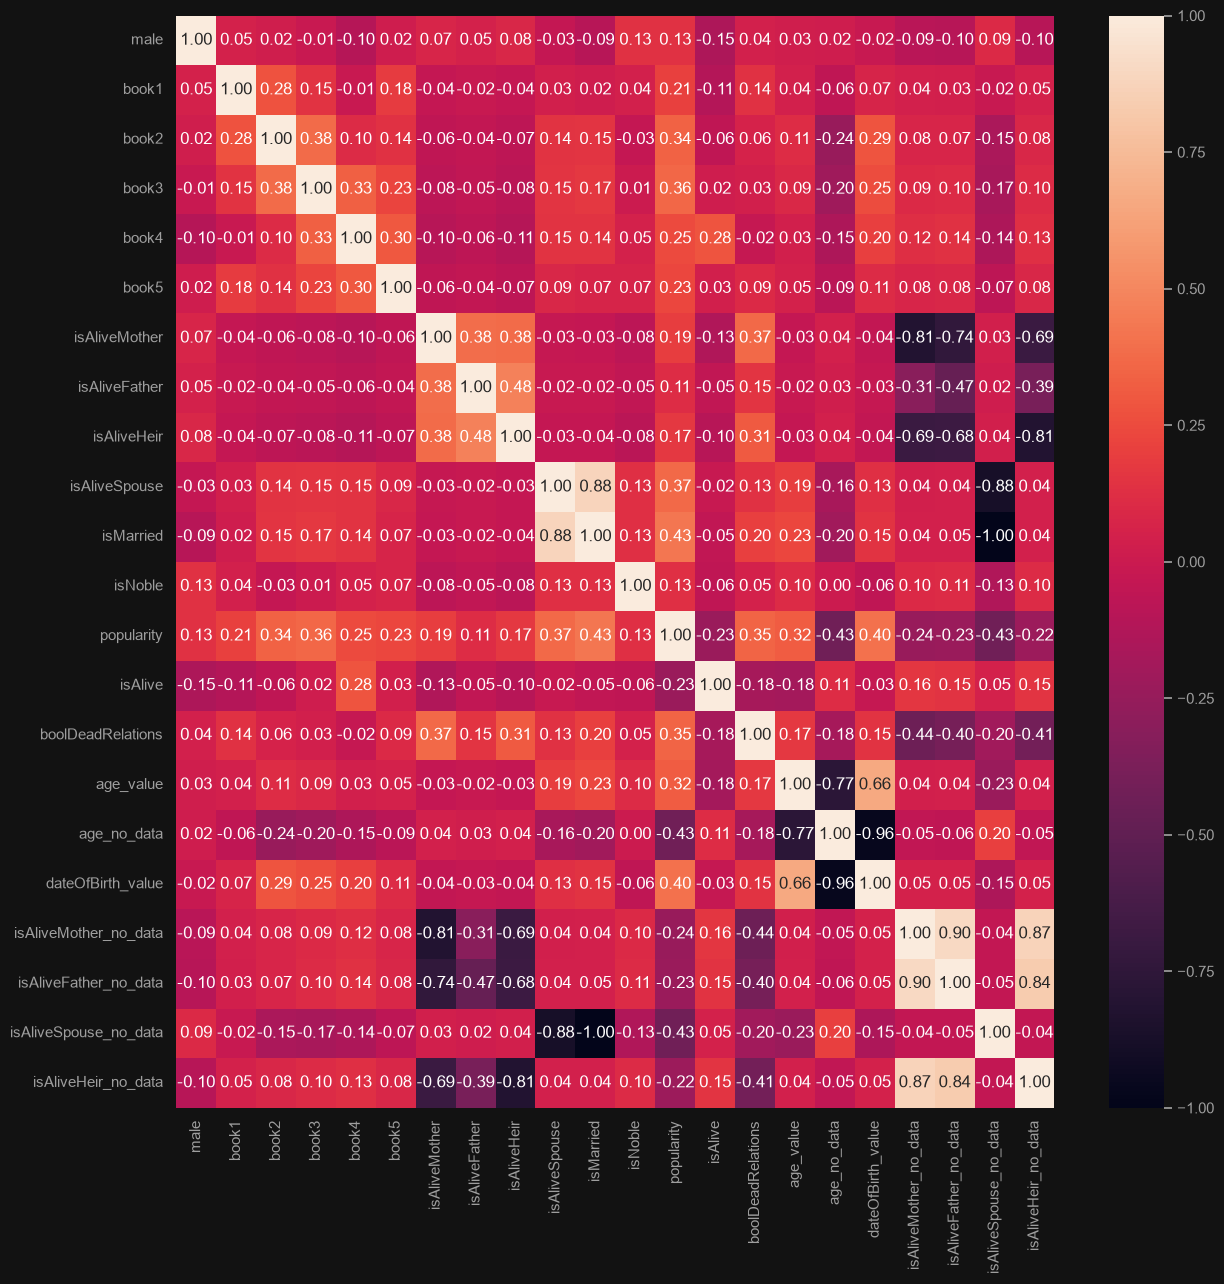

In [1714]:
plt.figure(figsize=(13, 13))
sns.heatmap(corr_matrix, annot=True, fmt=".2f")

plt.tight_layout()
plt.show()

Закодируем категориальные признаки с помощью OneHotEncoder

In [1715]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector

In [1716]:
preprocessor = ColumnTransformer(
    transformers=[
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), 
         make_column_selector(dtype_include=["object", "category"]))
    ],
    remainder="passthrough"
)

In [1717]:
preprocessor.set_output(transform="pandas")

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ohe', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. 

In [1718]:
data_encoded = preprocessor.fit_transform(data.drop("isAlive", axis=1))

In [1719]:
data_encoded.head()

,ohe__name_(guard),ohe__name_Arryn,ohe__name_Beesbury,ohe__name_Botley,ohe__name_Bracken,ohe__name_Brax,ohe__name_Caswell,ohe__name_Crakehall,ohe__name_Darry,ohe__name_Drumm,...,remainder__isNoble,remainder__popularity,remainder__boolDeadRelations,remainder__age_value,remainder__age_no_data,remainder__dateOfBirth_value,remainder__isAliveMother_no_data,remainder__isAliveFather_no_data,remainder__isAliveSpouse_no_data,remainder__isAliveHeir_no_data
S.No,,,,,,,,,,,,,,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,2.193298,1.0,0.0,1,0.0,0,0,1,0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1,2.197486,1.0,97.0,0,208.0,1,1,0,1
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1,2.070930,0.0,0.0,1,0.0,1,1,1,1
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1,1.867522,0.0,23.0,0,82.0,1,1,0,1
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1,0.259044,0.0,29.0,0,276.0,1,1,0,1


**Задание 1.8.** Проанализируйте влияние признаков на целевую переменную.

Посмотрим, как фамилия и титул влияют на выживаемость

Проверим сначала влияние фамилии на целевую переменную

In [1720]:
# Для примера возьмем 9 значимых фамилий, кроме мало упоминаемых

data["name"].value_counts().drop(index="rarely_encoding").sort_values(ascending=False)[:9]

name
Frey         72
Targaryen    27
Stark        26
Tyrell       24
Lannister    18
Vance        14
Hightower    12
Botley       11
Florent      11
Name: count, dtype: int64

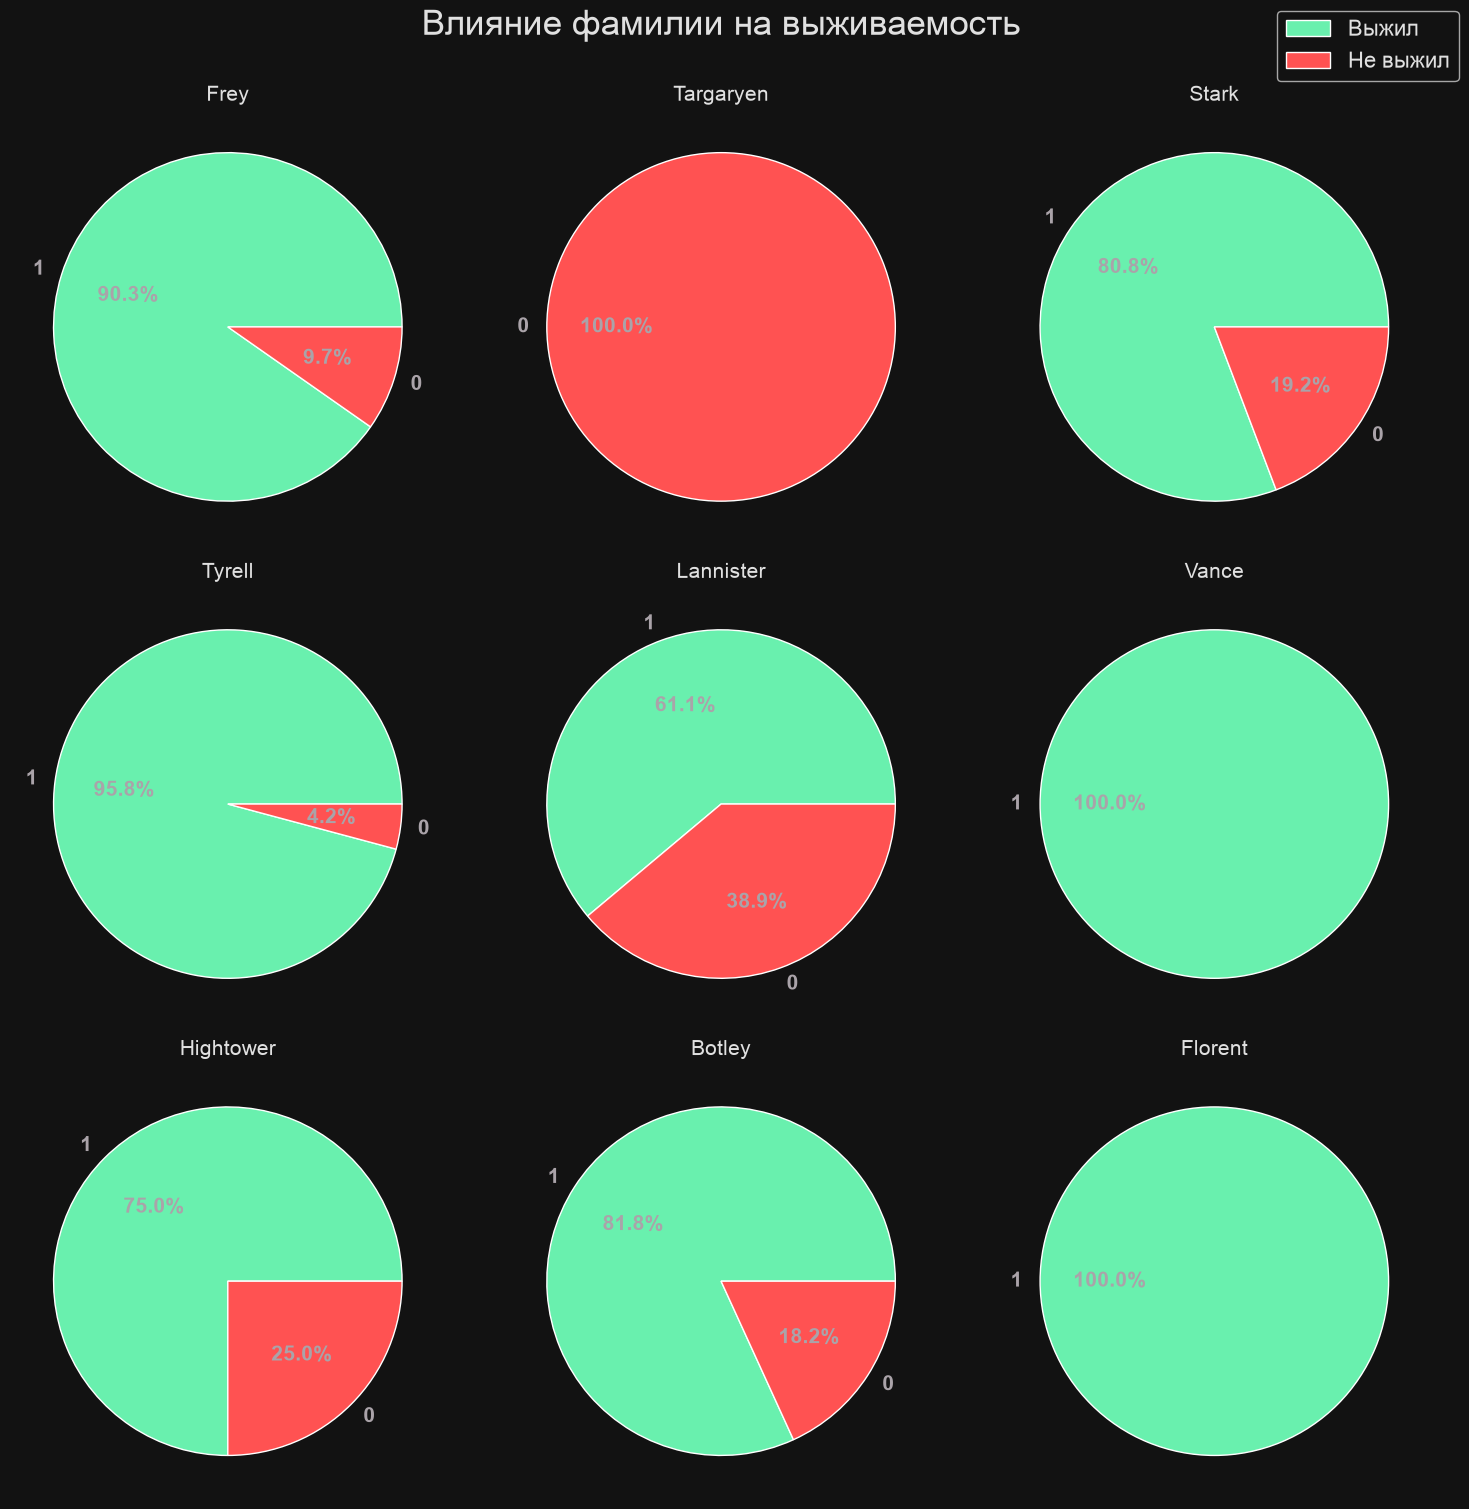

In [1721]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 15))
fig.suptitle("Влияние фамилии на выживаемость", size=25, y=1.005)

color_map = {
    0: '#FF5252',
    1: '#69F0AE'
}

names = data["name"].value_counts().drop(index="rarely_encoding").sort_values(ascending=False)[:9].index.tolist()

k = 0
for ax in axes:
    for a in ax:
        row = data[data["name"] == names[k]]["isAlive"].value_counts()
        
        pie_colors = [color_map[label] for label in row.index]
        a.pie(row, labels=row.index, autopct='%1.1f%%', textprops={"fontsize": 15, "color": "#AAA3A9", "weight": "bold"}, colors=pie_colors)
        a.set_title(names[k], size=15)

        k += 1

fig.legend(["Выжил", "Не выжил"], fontsize=16, markerscale=1.5)
plt.tight_layout()
plt.show()

Влияние статуса на выживаемость

In [1722]:
# Для примера возьмем 10 значимых титулов, кроме мало упоминаемых и отсутствующих

data["title"].value_counts().drop(index=["title_no_data", "rarely_encoding"]).sort_values(ascending=False)[:10]

title
Ser                  306
Maester               29
Archmaester           21
Lord                  19
Septon                16
Winterfell            15
Lady                  10
Princess               9
Septa                  9
King in the North      9
Name: count, dtype: int64

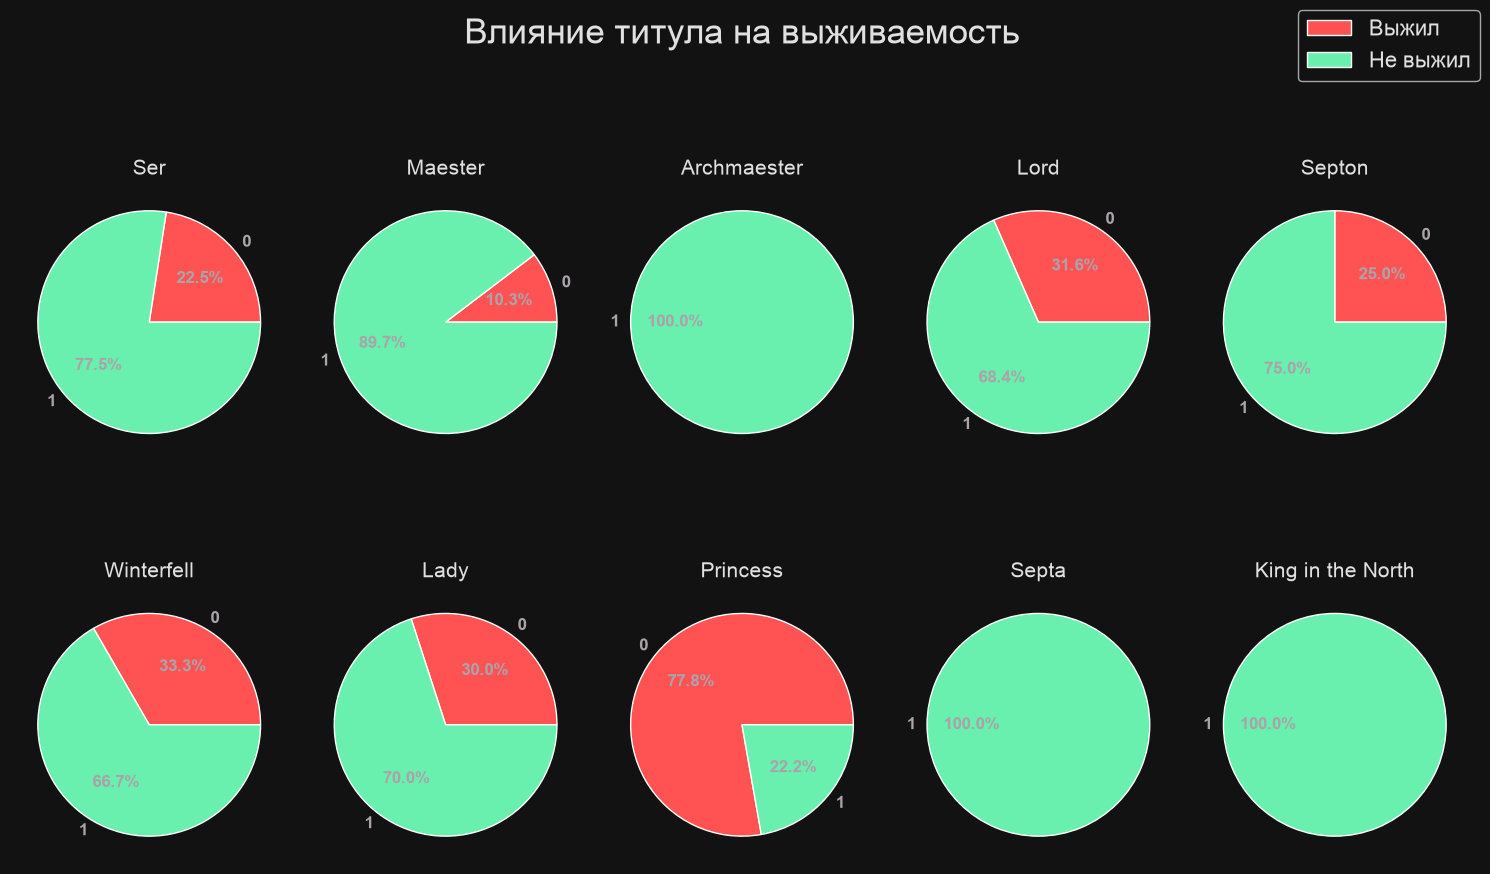

In [1723]:
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(15, 10))
fig.suptitle("Влияние титула на выживаемость", size=25)

color_map = {
    0: '#FF5252',
    1: '#69F0AE'
}

titles = data["title"].value_counts().drop(index=["title_no_data", "rarely_encoding"]).sort_values(ascending=False)[:10].index.tolist()

k = 0
for ax in axes:
    for a in ax:
        row = data[data["title"] == titles[k]]["isAlive"].value_counts().sort_index()

        pie_colors = [color_map[label] for label in row.index]
        a.pie(row, labels=row.index, autopct='%1.1f%%', textprops={"fontsize": 12, "color": "#AAA3A9", "weight": "bold"}, colors=pie_colors)
        a.set_title(titles[k], size=15)
        
        k += 1

fig.legend(["Выжил", "Не выжил"], fontsize=16, markerscale=1.5)
plt.tight_layout()
plt.show()

**Задание 1.9.** Создайте переменные `X`, которая будет хранить только значения признаков, которые вы отобрали для включения в модель, и `y`, которая будет хранить только значения целевой переменной.

In [1724]:
X = data_encoded
y = data["isAlive"]

In [1725]:
X.shape, y.shape

((1557, 172), (1557,))

**Задание 1.10.** Разделите датасет обучащую и валидационные части (train и val) при помощи функции `train_test_split` (https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)

In [1726]:
from sklearn.model_selection import train_test_split

In [1727]:
# не забудьте в функции train_test_split задать параметр random_state,
# чтобы обеспечить повторяемость разбиения выборки на train и validation части.
# Это позволит сравнивать метрики моделей с различными методами подготовки признаков

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=21, shuffle=True)

## Часть 2. Обучение моделей

В данной части домашнего задания, мы хотим научиться обучать модели для задачи классификации на наших данных.

**Задание 2.1.**


Вы можете работать с одной из предложенных моделей из библиотеки `sklearn`
* LogisticRegression
* RandomForestClassifier
* AdaBoostClassifier
* GaussianProcessClassifier
* GaussianNB
* KNeighborsClassifier
* SVC
* DecisionTreeClassifier


Однако в этом домашнем задании мы предлагаем выбрать и поработать с моделью `LogisticRegression`.

In [1728]:
from sklearn.linear_model import LogisticRegression

Импортируйте остальные модели из библиотеки `sklearn`. Чтобы понять как это сделать, воспользуйтесь официальный документацией `sklearn` $→$ [тык](https://scikit-learn.org/dev/user_guide.html). По ключевому названию модели, вы сможете найти необходимую информацию о том, как можно импортировать модель из библиотеки.

**Задание 2.2.** Обучите модель и сделайте предсказание на тестовой выборке

В качестве примера, обучим модель `LogisticRegression` и сделаем на ней предсказания на тестовой выборке.

In [1729]:
# Шаг 1. создание модели
model = LogisticRegression()

# Шаг 2. обучение модели
model.fit(X_train, y_train)

# Шаг 3. Предсказание на тестовых данных
y_pred = model.predict(X_val)

/Users/daniilafonin/deep-learning-school/MarshallErnestne/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Часть 3. Оцените качество моделей

Вам необходимо познакомиться с метриками задачи классификации из sklearn. Оцените все модели и выберите лучшую по метрике качества Accuracy.

С метриками классификации вы можете ознакомиться в [Yandex ML Book](https://education.yandex.ru/handbook/ml/article/metriki-klassifikacii-i-regressii).

Для простоты в данном домашнем задании мы будем работать с самой базовой метрикой для задачи классификации - accuracy.

**Задание 3.1.** Вам необходимо посчитать метрику для всех моделей и выбрать лучшую модель.

Сначала импортируем необходимую функцию из библиотеки sklearn для подсчета accuracy.

In [1730]:
from sklearn.metrics import accuracy_score

В качестве примера, посчитаем метрику accuracy для модели `LogisticRegression`

In [1731]:
# Шаг 4. Оценка предсказания по метрике accuracy

accuracy = accuracy_score(y_val, y_pred)
print("Accuracy : %.4f" % accuracy)

Accuracy : 0.8077


Оценим точность модели на train данных

In [1732]:
accuracy_train = accuracy_score(y_train, model.predict(X_train))
print("Accuracy : %.4f" % accuracy_train)

Accuracy : 0.8378


Оценим наивные модели

In [1733]:
accuracy_score(y_train, np.full_like(y_train, 0))

0.22008032128514057

In [1734]:
accuracy_score(y_train, np.full_like(y_train, 1))

0.7799196787148595

In [1735]:
accuracy_score(y_val, np.full_like(y_val, 0))

0.22756410256410256

In [1736]:
accuracy_score(y_val, np.full_like(y_val, 1))

0.7724358974358975

Возможно, вы решите вернуться на несколько шагов и попробовать другие варианты преобразования и подбора признаков в модель. **Выберите** лучшую модель.

### Тестовый датасет

В самом начале нашего домашнего задания мы скачивали тестовый датасет. Загрузите его в Pandas DataFrame при помощи функции read_csv

In [1737]:
data_test = pd.read_csv("../data/game_of_thrones_test.csv", index_col="S.No")

По аналогии с тем, как мы работали с обучающим датасетом, давайте посмотрим в тестовом датасете на статистики признаков с разными типами данных  

In [1738]:
#Подсказка
data_test.loc[data_test['age']<0] # Находим данные с ошибками в дате рождения и возрасте

,name,title,male,culture,dateOfBirth,mother,father,heir,house,spouse,...,book5,isAliveMother,isAliveFather,isAliveHeir,isAliveSpouse,isMarried,isNoble,age,numDeadRelations,popularity
S.No,,,,,,,,,,,,,,,,,,,,,
1685,Doreah,NaN,0,Lysene,278279.0,NaN,NaN,NaN,House Targaryen,NaN,...,1,NaN,NaN,NaN,NaN,0,0,-277980.0,0,0.110368
1869,Rhaego,NaN,0,NaN,298299.0,NaN,NaN,NaN,House Targaryen,NaN,...,0,NaN,NaN,NaN,NaN,0,0,-298001.0,6,0.167224


In [1739]:
#Вы можете аккуратно поправить тестовые данные, воспользовавшись, например следующим кодом:

data_test.loc[1685, 'dateOfBirth'] = 278
data_test.loc[1869, 'dateOfBirth'] = 299

data_test.loc[1685, 'age'] = 0
data_test.loc[1869, 'age'] = 0

# замены в строке 1685: dateOfBirth -> 278. и age -> 0.
# замены в строке 1869: dateOfBirth -> 299. и age -> 0.

Преобразуйте признаки в тестовом датасете по тому же пайплайну, как вы преобразовывали обучающие данные. Примените вашу лучшую модель на тестовом датасете для получения прогноза целевой переменной `isAlive`

In [1740]:
# Поработаем с Popularity

data_test["popularity"] = pd.Series(pt.transform(data_test[["popularity"]])[:, 0], name="popularity", index=data_test.index)

In [1741]:
# Поработаем с numDeadRelations

data_test.loc[data_test["numDeadRelations"] > 0, "boolDeadRelations"] = 1
data_test.loc[data_test["numDeadRelations"] == 0, "boolDeadRelations"] = 0

data_test.drop("numDeadRelations", axis=1, inplace=True)

In [1742]:
# Поработаем с AgeValue и DateOfBirth

data_test['age_value'] = [0 if np.isnan(x) else x for x in data_test["age"]]
data_test['age_no_data'] = [1 if np.isnan(x) else 0 for x in data_test['age']]

data_test.drop("age", axis=1, inplace=True)

data_test["dateOfBirth_value"] = [0 if np.isnan(x) else x for x in data_test["dateOfBirth"]]

data_test.drop("dateOfBirth", axis=1, inplace=True)

In [1743]:
# Поработаем с Culture

data_test['culture_grouped'] = data_test['culture'].str.lower().map(cultures_grouped_inverted)
data_test["culture_grouped"] = data_test["culture_grouped"].fillna("culture_no_data")

data_test.drop("culture", axis=1, inplace=True)

In [1744]:
# Поработаем с оставшимеся признаками

data_test["name"] = data_test["name"].map(lambda field: field.split(" ")[-1])

feature_preprocessing_ht(data_test, "house", 5)
feature_preprocessing_ht(data_test, "title", 5)

feature_preprocessing_mfsh(data_test, "mother", 5)
feature_preprocessing_mfsh(data_test, "father", 5)
feature_preprocessing_mfsh(data_test, "spouse", 5)
feature_preprocessing_mfsh(data_test, "heir", 5)

In [1745]:
# Закодируем категориальные признаки

data_test_encoded = preprocessor.transform(data_test)

In [1746]:
# Сделаем предсказание на тестовой выборке

predict_test = model.predict(data_test_encoded)

### Файл `submission.csv`

Вам нужно вместо значений в `submission.csv` файле в колонке `isAlive`, подставить свои предсказания и сохранить измененный файл.

In [1747]:
!gdown 1M14conWjAW2QLoyCXbHEAy8bql2f99eF

zsh:1: command not found: gdown


In [1748]:
# submission = pd.read_csv("/content/submission.csv", index_col='S.No')

In [1749]:
# submission

Как сохранить измененный Pandas DataFrame в csv файл:

In [1750]:
# submission.to_csv("/content/new_submission.csv", index=False)